# Движок анализа A/B-экспериментов: что внутри и почему так

Ноутбук — разбор методов пакета `abengine`. Каждое решение проверено не формулой, а симуляцией:
3 000 экспериментов на свежих популяциях — 2 000 A/A (эффекта нет) и 1 000 A/B (эффект есть).
Правильная процедура держит долю ложных срабатываний на уровне α = 5 % и при этом ловит эффект как можно чаще.

| Раздел | Вопрос |
|---|---|
| 1. Данные и метрики | Как логи превращаются в метрики и почему единица анализа — пользователь |
| 2. Единица анализа | Что будет, если считать CTR по просмотрам, а средний чек — по заказам |
| 3. CUPED | Сколько трафика экономит история пользователя до эксперимента |
| 4. Подглядывание | Почему нельзя смотреть каждый день и что делать вместо этого |
| 5. Много метрик | Зачем поправка Холма |
| 6. SRM | Как сломанный сплит выдаёт себя и почему его результатам нельзя верить |
| 7. Итог | Чек-лист анализа |

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from abengine import stats
from abengine.analysis import analyze, test_metric
from abengine.dataset import generate, write_duckdb
from abengine.metrics import METRICS, daily_metrics, experiment_info, user_metrics

pd.options.display.float_format = "{:,.4f}".format
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
IMG = ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
DB = ROOT / "data" / "shop.duckdb"
if not DB.exists():
    tables, _ = generate()
    write_duckdb(tables, DB)
con = duckdb.connect(str(DB), read_only=True)
aa = pd.read_csv(ROOT / "results" / "validation_aa.csv")
ab = pd.read_csv(ROOT / "results" / "validation_ab.csv")
rate = lambda df, col, thr=0.05: (df[col] < thr).mean()
ci95 = lambda p, n: 1.96 * np.sqrt(p * (1 - p) / n)
print(f"A/A: {len(aa)} экспериментов, A/B: {len(ab)}")

A/A: 2000 экспериментов, A/B: 1000


## 1. Данные и метрики

Синтетические логи интернет-магазина в DuckDB (`python -m abengine generate`): 150 000 пользователей,
4 недели истории и 3 недели экспериментов. У каждого пользователя устойчивые черты — как часто заходит,
кликает, покупает, какой у него чек, — поэтому поведение до эксперимента предсказывает поведение во время.

Таблицы — как в хранилище событий: `users`, `daily_activity`, `orders`, `experiments`, `assignments`.
Назначение — по хешу `md5(соль:user_id)`: детерминированно и независимо между экспериментами с разными солями.
В эксперимент пользователь попадает в день первого захода; метрики считаются с этого дня.

In [2]:
con.sql("SELECT table_name, estimated_size AS rows FROM duckdb_tables() ORDER BY table_name").df()

,table_name,rows
0,assignments,472658
1,daily_activity,1362587
2,experiments,4
3,orders,80777
4,users,150000


In [3]:
users = user_metrics(con, "checkout_redesign")
print(f"Пользователей в эксперименте: {len(users):,}".replace(",", " "))
users.head()

Пользователей в эксперименте: 118 739


,user_id,variant,platform,exposure_day,views,clicks,all_orders,orders,cancelled,revenue,buyer,pre_views,pre_clicks,pre_all_orders,pre_orders,pre_cancelled,pre_revenue,pre_buyer
0,1,treatment,android,6,18.0000,1.0000,0,0,0,0.0000,0,26.0000,3.0000,0,0,0,0.0000,0
1,2,treatment,ios,1,42.0000,4.0000,1,1,0,"5,587.9000",1,46.0000,3.0000,0,0,0,0.0000,0
2,4,control,web,5,11.0000,1.0000,0,0,0,0.0000,0,21.0000,3.0000,0,0,0,0.0000,0
3,5,treatment,web,0,48.0000,12.0000,2,2,0,"13,852.1700",1,44.0000,9.0000,0,0,0,0.0000,0
4,7,control,web,8,8.0000,1.0000,0,0,0,0.0000,0,3.0000,1.0000,0,0,0,0.0000,0


SQL (`metrics.py`) сводит события к **пользовательским суммам**: просмотры, клики, заказы, выручка, отмены —
за период эксперимента и за 28 дней до него (`pre_*` — ковариаты для CUPED). Метрики двух видов:

* **средние по пользователям** — конверсия (есть ли оплаченный заказ), выручка на пользователя;
* **отношения сумм** — средний чек = Σвыручка / Σзаказы, CTR = Σклики / Σпросмотры, доля отмен.

## 2. Единица анализа: пользователь, а не заказ

Делили пользователей — значит, независимы пользователи, а не их заказы и просмотры. Просмотры одного
пользователя похожи друг на друга: «кликучий» пользователь кликает часто во всех своих просмотрах.
t-тест по просмотрам считает их независимыми и занижает дисперсию в разы. Для отношений правильный путь —
дельта-метод по пользовательским суммам: дисперсия Σx/Σy через дисперсии и ковариацию числителя и знаменателя.

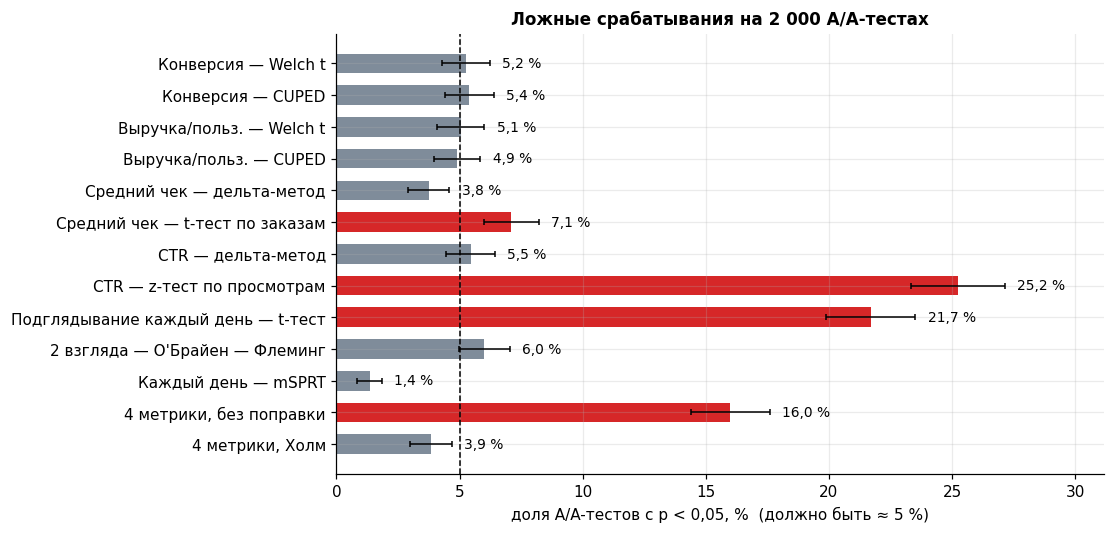

In [4]:
rows = [("conv_welch", "Конверсия — Welch t"), ("conv_cuped", "Конверсия — CUPED"),
        ("arpu_welch", "Выручка/польз. — Welch t"), ("arpu_cuped", "Выручка/польз. — CUPED"),
        ("aov_delta", "Средний чек — дельта-метод"), ("aov_naive", "Средний чек — t-тест по заказам"),
        ("ctr_delta", "CTR — дельта-метод"), ("ctr_naive", "CTR — z-тест по просмотрам"),
        ("peek_fixed_any", "Подглядывание каждый день — t-тест"), ("peek_obf_any", "2 взгляда — О'Брайен — Флеминг"),
        ("peek_msprt_any", "Каждый день — mSPRT"),
        ("family_min_raw", "4 метрики, без поправки"), ("family_min_holm", "4 метрики, Холм")]
fpr = pd.DataFrame([(label, rate(aa, col)) for col, label in rows], columns=["Процедура", "Ложные срабатывания"])
fpr["±95 %"] = ci95(fpr["Ложные срабатывания"], len(aa))
bad = fpr["Ложные срабатывания"] - fpr["±95 %"] > 0.05

fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(fpr))[::-1]
ax.barh(y, 100 * fpr["Ложные срабатывания"], xerr=100 * fpr["±95 %"], color=np.where(bad, "#d62728", "#7f8c9a"),
        height=0.62, error_kw=dict(lw=1, capsize=2))
ax.axvline(5, color="black", ls="--", lw=1)
ax.set_yticks(y, fpr["Процедура"])
ax.set_xlabel("доля A/A-тестов с p < 0,05, %  (должно быть ≈ 5 %)")
ax.set_title(f"Ложные срабатывания на {len(aa):,} A/A-тестах".replace(",", " "))
for yi, v, e in zip(y, fpr["Ложные срабатывания"], fpr["±95 %"]):
    ax.text(100 * (v + e) + 0.5, yi, f"{100 * v:.1f} %".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(0, 100 * (fpr["Ложные срабатывания"] + fpr["±95 %"]).max() + 4)
fig.savefig(IMG / "false_positives.png")

Красные — процедуры, которые врут: доверительный интервал доли целиком выше 5 %. CTR, посчитанный по просмотрам,
ошибается в каждом четвёртом A/A-тесте. У среднего чека эффект слабее — заказов на пользователя мало, — но тоже есть.
Дельта-метод держит 5 %. Проверим его и на реальном эксперименте — сравнением с бутстрепом по пользователям:

In [5]:
c = users[users.variant == "control"]
r, var_r = stats.ratio_moments(c.revenue.to_numpy(float), c.orders.to_numpy(float))
rng = np.random.default_rng(0)
boot = []
num, den = c.revenue.to_numpy(float), c.orders.to_numpy(float)
for _ in range(1000):
    i = rng.integers(0, len(c), len(c))
    boot.append(num[i].sum() / den[i].sum())
orders = con.sql("SELECT o.revenue::DOUBLE AS revenue FROM orders o JOIN assignments a USING (user_id) "
                 "WHERE a.experiment_id = 'checkout_redesign' AND a.variant = 'control' AND o.status = 'completed' "
                 "AND o.order_date >= a.first_exposure").df().revenue
pd.DataFrame({"SE среднего чека, ₽": [np.sqrt(var_r), np.std(boot), orders.std() / np.sqrt(len(orders))]},
             index=["дельта-метод", "бутстреп по пользователям (1000)", "по заказам как независимым"])

,"SE среднего чека, ₽"
дельта-метод,29.5228
бутстреп по пользователям (1000),29.0937
по заказам как независимым,25.1001


Дельта-метод совпадает с бутстрепом за доли секунды вместо тысячи пересчётов — поэтому его и используют
платформы экспериментов. Для CUPED по отношениям в пакете есть **линеаризация** (Budylin et al., 2018):
`L = (x − R_c·y) / ȳ_c` — пользовательская метрика, среднее которой даёт ту же разность отношений;
к ней применимо всё, что работает для средних.

## 3. CUPED: история пользователя вместо дополнительного трафика

Дисперсия метрики во многом объясняется тем, какой пользователь *вообще*: активный покупает чаще в любой
группе. CUPED вычитает из метрики её значение до эксперимента: Ŷ = Y − θ(X − X̄), θ = cov(Y, X)/var(X).
X не зависит от назначения, поэтому оценка эффекта остаётся несмещённой, а дисперсия падает в (1 − ρ²) раз.

In [6]:
vr = []
for key, m in METRICS.items():
    raw, final = test_metric(users, m)
    red = final.extra["variance_reduction"]
    vr.append((m.title, red, 1 / (1 - red) - 1, raw.se / final.se - 1))
vr = pd.DataFrame(vr, columns=["Метрика", "Снижение дисперсии", "≈ экономия трафика", "Сужение интервала"]).set_index("Метрика")
vr.style.format("{:.0%}")

,Снижение дисперсии,≈ экономия трафика,Сужение интервала
Метрика,,,
Конверсия в покупку,12%,14%,7%
Выручка на пользователя,19%,23%,11%
Средний чек,13%,14%,4%
CTR карточек товара,53%,111%,45%
Доля отменённых заказов,0%,0%,-2%


,без CUPED,CUPED
Конверсия,50.0%,53.8%
Выручка на пользователя,72.5%,79.1%


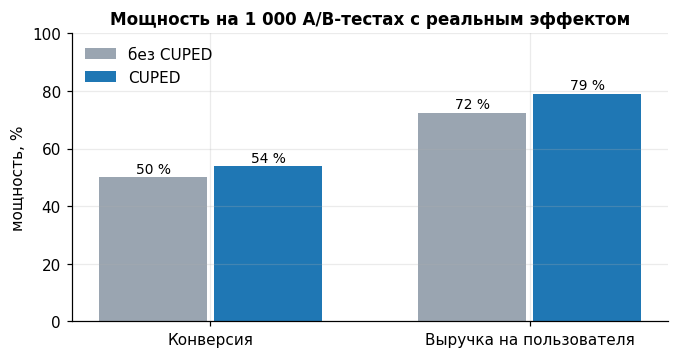

In [7]:
power = pd.DataFrame({
    "без CUPED": [rate(ab, "conv_welch"), rate(ab, "arpu_welch")],
    "CUPED": [rate(ab, "conv_cuped"), rate(ab, "arpu_cuped")],
}, index=["Конверсия", "Выручка на пользователя"])
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(power))
for k, (col, color) in enumerate([("без CUPED", "#9aa5b1"), ("CUPED", "#1f77b4")]):
    ax.bar(x + (k - 0.5) * 0.36, 100 * power[col], width=0.34, color=color, label=col)
    for xi, v in zip(x, power[col]):
        ax.text(xi + (k - 0.5) * 0.36, 100 * v + 1.5, f"{100 * v:.0f} %", ha="center", fontsize=9)
ax.set_xticks(x, power.index)
ax.set_ylabel("мощность, %")
ax.set_ylim(0, 100)
ax.set_title(f"Мощность на {len(ab):,} A/B-тестах с реальным эффектом".replace(",", " "))
ax.legend(frameon=False)
fig.savefig(IMG / "cuped_power.png")
power.style.format("{:.1%}")

CUPED сохраняет ложные срабатывания на 5 % (см. раздел 2) и поднимает мощность. Самый большой выигрыш —
у CTR: снижение дисперсии больше 50 %, то есть тот же результат на вдвое меньшем трафике.

## 4. Подглядывание

Классический тест рассчитан на один взгляд в конце. Если смотреть каждый день и остановиться при первом p < 0,05,
шансов «поймать» случайный выброс 14 раз больше — ложных срабатываний становится 20 % вместо 5 %. Два решения:

* **О'Брайен — Флеминг** — несколько *запланированных* взглядов с жёсткими ранними границами
  (для двух равных по объёму взглядов: |Z| > 2,80 на первом и > 1,98 на втором): мощность почти как у одного взгляда;
* **mSPRT** (Johari et al., 2017) — всегда-валидные p-value: смотреть можно когда угодно и сколько угодно,
  ценой мощности.

,Ложные срабатывания,Мощность
Один взгляд в конце,5.2%,50.0%
"Каждый день, t-тест",21.7%,71.7%
"2 взгляда, О'Брайен — Флеминг",6.0%,52.1%
"Каждый день, mSPRT",1.4%,23.7%


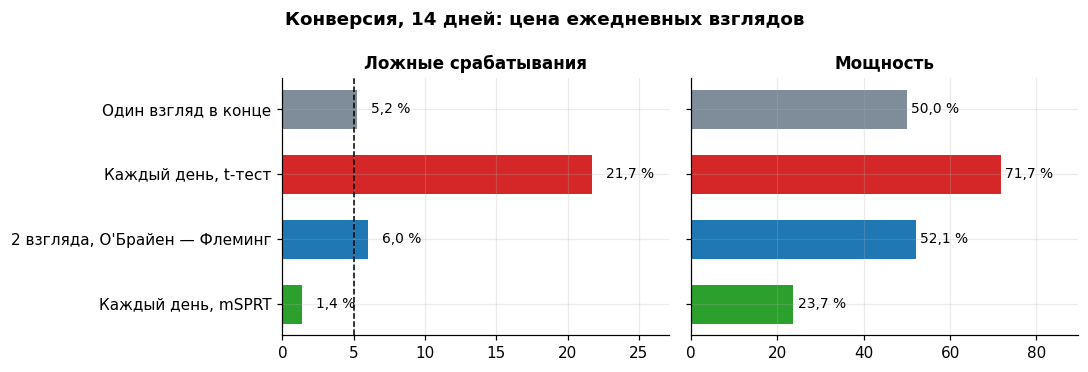

In [8]:
seq = pd.DataFrame({
    "Ложные срабатывания": [rate(aa, "conv_welch"), rate(aa, "peek_fixed_any"), rate(aa, "peek_obf_any"), rate(aa, "peek_msprt_any")],
    "Мощность": [rate(ab, "conv_welch"), rate(ab, "peek_fixed_any"), rate(ab, "peek_obf_any"), rate(ab, "peek_msprt_any")],
}, index=["Один взгляд в конце", "Каждый день, t-тест", "2 взгляда, О'Брайен — Флеминг", "Каждый день, mSPRT"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
colors = ["#7f8c9a", "#d62728", "#1f77b4", "#2ca02c"]
for ax, col, ref in zip(axes, seq.columns, [5, None]):
    ax.barh(np.arange(4)[::-1], 100 * seq[col], color=colors, height=0.6)
    for yi, v in zip(np.arange(4)[::-1], seq[col]):
        ax.text(100 * v + 1, yi, f"{100 * v:.1f} %".replace(".", ","), va="center", fontsize=9)
    if ref:
        ax.axvline(ref, color="black", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlim(0, 100 * seq[col].max() * 1.25)
axes[0].set_yticks(np.arange(4)[::-1], seq.index)
fig.suptitle("Конверсия, 14 дней: цена ежедневных взглядов", fontweight="bold")
fig.tight_layout()
fig.savefig(IMG / "peeking.png")
seq.style.format("{:.1%}")

Ежедневный t-тест «мощнее» только потому, что чаще срабатывает вообще — в том числе ложно. О'Брайен — Флеминг
почти не теряет мощности и позволяет остановиться на 7-й день при сильном эффекте. mSPRT платит мощностью за
полную свободу. Его доля ложных срабатываний 1,4 % < 5 % — граница консервативна, а не точна.
Как это выглядит в отчёте — накопленный эффект «Нового чекаута» с обычным и всегда-валидным интервалами:

,day,users,lift,p_fixed,p_msprt
0,1,26479,0.0204,0.6837,1.0000
6,7,88137,0.0373,0.0507,0.7636
13,14,109006,0.0346,0.0117,0.1433
20,21,118739,0.0303,0.0081,0.0574


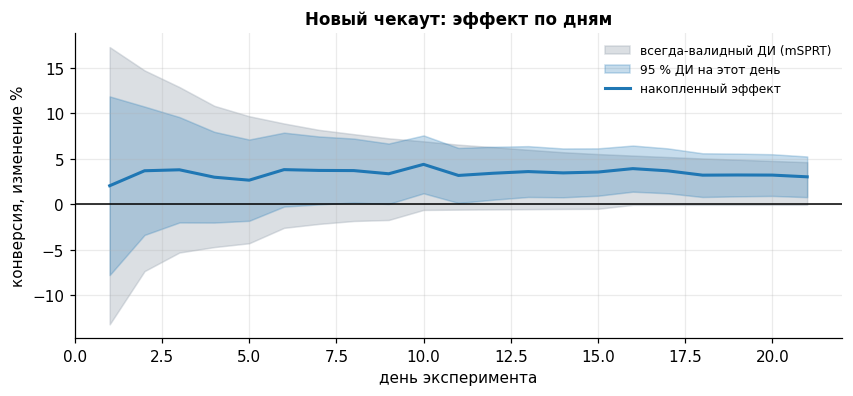

In [9]:
a = analyze(users, daily_metrics(con, "checkout_redesign"), experiment_info(con, "checkout_redesign"))
s = a.sequential
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(s.day, 100 * s.av_lift_lo.clip(-0.2), 100 * s.av_lift_hi.clip(upper=0.2), color="#9aa5b1", alpha=0.35, label="всегда-валидный ДИ (mSPRT)")
ax.fill_between(s.day, 100 * s.lift_lo, 100 * s.lift_hi, color="#1f77b4", alpha=0.25, label="95 % ДИ на этот день")
ax.plot(s.day, 100 * s.lift, color="#1f77b4", lw=2, label="накопленный эффект")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("день эксперимента")
ax.set_ylabel("конверсия, изменение %")
ax.set_title("Новый чекаут: эффект по дням")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.savefig(IMG / "sequential.png")
s[["day", "users", "lift", "p_fixed", "p_msprt"]].iloc[[0, 6, 13, 20]]

## 5. Много метрик — поправка Холма

У эксперимента редко одна метрика. Если проверять четыре вторичные метрики без поправки, хотя бы одна окажется
«значимой» в 16 % A/A-тестов. Поправка Холма (шаговый Бонферрони) возвращает вероятность хотя бы одной ложной
находки к ≤ 5 % и при этом мощнее простого Бонферрони. Основная метрика — одна и заранее объявлена, ей поправка
не нужна; защитные метрики проверяются без поправки — пропустить вред дороже, чем лишний раз перепроверить.

In [10]:
pd.DataFrame({"Хотя бы одна ложная находка (A/A)": [rate(aa, "family_min_raw"), rate(aa, "family_min_holm")],
              "Хотя бы одна находка (A/B)": [rate(ab, "family_min_raw"), rate(ab, "family_min_holm")]},
             index=["без поправки", "Холм"]).style.format("{:.1%}")

,Хотя бы одна ложная находка (A/A),Хотя бы одна находка (A/B)
без поправки,16.0%,94.2%
Холм,3.9%,79.2%


## 6. SRM: когда результаты нельзя смотреть вообще

В «Баннере акции» встроен типичный баг: у малоактивных пользователей в treatment часть записей о назначении
теряется (медленная загрузка баннера — уход до логирования). Сплит перестаёт быть 50/50, и, главное, теряются
*неслучайные* пользователи — оставшиеся в treatment активнее. Это видно ещё до эксперимента:

In [11]:
rows = []
for exp in ["aa_platform_check", "promo_banner"]:
    u = user_metrics(con, exp)
    n = u.variant.value_counts()
    chi2, p = stats.srm_test(n["control"], n["treatment"])
    bal = stats.mean_test(*(u.loc[u.variant == v, "pre_revenue"].to_numpy(float) for v in ("control", "treatment")))
    rows.append((exp, n["control"], n["treatment"], p, bal.lift, bal.p_value))
pd.DataFrame(rows, columns=["Эксперимент", "control", "treatment", "SRM p", "Выручка ДО старта, разница", "p"]).set_index("Эксперимент")

,control,treatment,SRM p,"Выручка ДО старта, разница",p
Эксперимент,,,,,
aa_platform_check,59428,59311,0.7342,0.0254,0.1820
promo_banner,59230,57211,0.0000,0.0525,0.0067


χ²-тест на соотношение групп ловит поломку при p ≪ 0,001, а проверка баланса до старта показывает её следствие:
treatment «богаче» ещё до того, как увидел баннер. Любое сравнение после этого смещено, поэтому отчёт при SRM
не выносит решения по метрикам. Порог SRM строже обычного (0,001): проверка идёт в каждом эксперименте,
и ложная тревога дорога. На 2 000 честных A/A-тестах SRM-тест сработал ложно 1 раз — при пороге 0,001 ожидается около двух.

## 7. Чек-лист анализа

1. **Здоровье эксперимента до метрик:** SRM, баланс групп до старта, A/A-проверка платформы.
2. **Единица анализа = единица рандомизации.** Отношения — дельта-методом или линеаризацией, не по заказам.
3. **CUPED** на истории пользователя — бесплатная мощность: до −53 % дисперсии на этих данных.
4. **Одна основная метрика,** вторичные с поправкой Холма, защитные — без поправки.
5. **Длительность — заранее.** Хочется смотреть раньше — О'Брайен — Флеминг или mSPRT, но не ежедневный t-тест.
6. **Срезы — для гипотез,** а не для решений.